# 02. SO-101の初期姿勢と、順運動学（FK）・逆運動学（IK）の確認

**このノートブックで確かめたこと**

1. SO-101の関節構成と、グリッパー角の向き（何radで開き、何radで閉じるか）
2. 本研究で決め打ちした **初期姿勢** と **作業空間の中心** が、どのような構えになっているか
3. 姿勢の計算（FK）が正しく行えているか
4. 目標位置から関節角を求める計算（IK）が、どのような場合に成功し、どのような場合に失敗するか


In [1]:
# パス設定
from pathlib import Path

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"        # 外部から取得したデータの置き場所
OUT_DIR = ROOT / "outputs"      # このノートブックで作成する図・動画の置き場所

# Grabetteデータセット
GRABETTE_DIR = DATA_DIR / "grabette_pick3_cartesian_480"

# SO-101のMuJoCoモデル
MENAGERIE_DIR = DATA_DIR / "mujoco_menagerie"
MJCF_PATH = MENAGERIE_DIR / "robotstudio_so101" / "so101.xml"
# 描画用のシーン
SCENE_PATH = MENAGERIE_DIR / "robotstudio_so101" / "scene.xml"

OUT_DIR.mkdir(parents=True, exist_ok=True)
# print("ROOT         :", ROOT)
# print("GRABETTE_DIR :", GRABETTE_DIR)
# print("MJCF_PATH    :", MJCF_PATH)

In [2]:
# グラフスタイル設定

# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

In [3]:
import numpy as np

# 関節の並び順はMJCFの定義順と同じであり、学習データの列順もこれに従う。
JOINT_NAMES = ["shoulder_pan", "shoulder_lift", "elbow_flex",
               "wrist_flex", "wrist_roll", "gripper"]

# 以下SO-101姿勢に関する「決め打ち」の値。何回か試行錯誤の末、目測上破綻のない姿勢をとらせることにした。

# 手首の回転（wrist_roll）を固定する値: -90度
# この角度では、ジョーがロボットの左右方向（Y方向）に開く。
# Grabetteの映像でも2本の指は画面の左右にあり、物体を左右から挟む。その向きに合わせる。
WRIST_ROLL_FIXED = -np.pi / 2

# 初期姿勢（決め打ち）。IKを解き始める最初の関節角として使う。
Q_INIT_PICK = np.array([
    0.0,                 # shoulder_pan : 正面を向く
    np.radians(-10.0),   # shoulder_lift: 上腕をわずかに前へ倒す
    np.radians(15.0),    # elbow_flex   : 肘を少し曲げる
    np.radians(85.0),    # wrist_flex   : 手首を曲げてグリッパーの先端を下ろす
    WRIST_ROLL_FIXED,    # wrist_roll   : -90度（ジョーが左右に開く向き）
    0.0,                 # gripper      : IKでは動かさない関節なので値は使われない
], dtype=float)

# 作業空間の中心。初期姿勢Q_INIT_PICKのグリッパー位置（約[0.211, -0.012, 0.067]）の近くに置くことで、
# 軌跡の中心付近では初期姿勢のままIKが解けるようにしている。
WORKSPACE_CENTER = np.array([0.22, 0.0, 0.07])

# IKが収束しなかったときに、初期値を変えて解き直すための予備の初期姿勢。
Q_INIT_FALLBACKS = [
    np.array([0, np.radians(-15), np.radians(10), np.radians(85),
              WRIST_ROLL_FIXED, 0], dtype=float),
    np.array([0, np.radians(-20), np.radians(20), np.radians(80),
              WRIST_ROLL_FIXED, 0], dtype=float),
    np.array([0, np.radians(-5), np.radians(10), np.radians(80),
              WRIST_ROLL_FIXED, 0], dtype=float),
]

# グリッパー関節角とジョーの開き具合の対応（MuJoCoで実測。02で確認する）
SO101_GRIPPER_OPEN = 1.7453292    # 全開（ジョー間隔 約133 mm）
SO101_GRIPPER_CLOSED = 0.0        # 全閉（ジョー間隔 約16 mm）

In [4]:
# FK・IK計算関数群
# 計算ライブラリにはpinocchioを用いる
import pinocchio as pin

EE_FRAME = "gripperframe"     # グリッパー先端を表すMJCF上の名前

class SO101Kinematics:
    """SO-101（腕5関節 + グリッパー1関節）のFK / IKを計算するクラス。"""

    def __init__(self, mjcf_path):
        # MJCFからロボットモデルを作成し、計算用の作業領域（data）を確保する
        self.model = pin.buildModelFromMJCF(str(mjcf_path))
        self.data = self.model.createData()
        self.ee_id = self.model.getFrameId(EE_FRAME)
        # 関節の並び順が想定どおりかを確認する（違えば以降の計算がすべて狂う）
        names = [self.model.names[i] for i in range(1, self.model.njoints)]
        if names != JOINT_NAMES:
            raise ValueError(f"関節の並び順が想定と異なります: {names}")

    def joint_limits(self):
        """各関節の可動範囲（下限, 上限）[rad]を返す。"""
        return (self.model.lowerPositionLimit.copy(),
                self.model.upperPositionLimit.copy())

    def fk(self, q):
        """順運動学: 関節角qからグリッパー先端の位置・姿勢（SE3）を返す。"""
        q = np.asarray(q, dtype=float)
        pin.forwardKinematics(self.model, self.data, q)
        pin.updateFramePlacements(self.model, self.data)
        return self.data.oMf[self.ee_id].copy()

    def ik(self, target, q_init=None, max_iters=200, pos_tol=1e-4,
           rot_tol=1e-2, step=1.0, damping=1e-6, pos_weight=1.0,
           ori_weight=1e-4, locked_joints=(5,), history=None):
        """
        逆運動学: 目標target（pin.SE3）に届く関節角を反復計算で探す。

        計算の流れ（1回の反復）
        ------------------------
        1. 現在の関節角qでFKを計算し、グリッパー先端の現在位置を求める。
        2. 「現在 → 目標」のずれerr（位置3成分 + 姿勢3成分）を求める。
        3. ずれに重みを掛ける。位置の重みは1、姿勢の重みは1e-4とする。
           SO-101は腕が5関節しかなく、位置3 + 姿勢3の6自由度すべてを
           同時に合わせることは一般にできない。そこで姿勢はほぼ無視し、
           位置を合わせることを優先する。
        4. ヤコビアンJ（関節を少し動かすと先端がどれだけ動くかを表す行列）を使い、
           減衰付き最小二乗法で関節の修正量dqを求める。
               dq = Jw^T (Jw Jw^T + damping * I)^(-1) err_w
           dampingはJがほぼ特異（どの方向にも動けない姿勢）なときに
           dqが極端に大きくなるのを防ぐための小さな値である。
        5. qをdqだけ更新し、関節の可動範囲内に収める（範囲外の値は端に揃える）。

        locked_jointsに指定した関節（既定ではグリッパー）はJの列を0にするため、
        IKでは一切動かず、q_initの値のまま残る。

        引数historyにリストを渡すと、反復ごとの位置誤差[m]を記録する
        （収束の様子を図示するための補助機能で、計算結果には影響しない）。

        戻り値
        ------
        q        : (6,)最終的な関節角
        success  : 位置誤差がpos_tol未満ならTrue
        pos_err  : 最終的な位置誤差[m]（FKで計算し直した値）
        """
        if q_init is not None:
            q = q_init.copy().astype(float)
        else:
            # 初期値が無い場合は、全関節0（pinocchioの基準姿勢）から始める
            q = pin.neutral(self.model).astype(float)
        weight = np.diag([pos_weight] * 3 + [ori_weight] * 3)

        for _ in range(max_iters):
            # 手順1: 現在の先端位置
            pin.forwardKinematics(self.model, self.data, q)
            pin.updateFramePlacements(self.model, self.data)
            current = self.data.oMf[self.ee_id]

            # 手順2: 現在から目標までのずれ（先端自身の座標系で表した6成分）
            err = pin.log6(current.actInv(target)).vector
            pos_err = float(np.linalg.norm(err[:3]))
            if history is not None:
                history.append(pos_err)
            # 位置・姿勢とも十分に小さければ反復を打ち切る
            # （姿勢の重みが小さいため、実際には上限回数まで回ることが多い）
            if pos_err < pos_tol and np.linalg.norm(err[3:]) < rot_tol:
                break

            # 手順3: 重み付け
            err_w = weight @ err

            # 手順4: ヤコビアンと減衰付き最小二乗法
            jac = pin.computeFrameJacobian(self.model, self.data, q,
                                           self.ee_id, pin.LOCAL)
            for j in locked_joints:
                jac[:, j] = 0.0
            jac_w = weight @ jac
            dq = jac_w.T @ np.linalg.solve(
                jac_w @ jac_w.T + damping * np.eye(6), err_w)

            # 手順5: 更新と可動範囲への制限
            q = pin.integrate(self.model, q, step * dq)
            q = np.clip(q, self.model.lowerPositionLimit,
                        self.model.upperPositionLimit)

        # 最終結果をFKで確かめ直し、目標との位置の差を誤差とする
        pin.forwardKinematics(self.model, self.data, q)
        pin.updateFramePlacements(self.model, self.data)
        pos_err = float(np.linalg.norm(
            self.data.oMf[self.ee_id].translation - target.translation))
        return q, pos_err < pos_tol, pos_err

In [5]:
# ============================================================
# MuJoCoによるSO-101の描画と自己衝突の判定
# ============================================================
# 関節角をセットしてMuJoCoの描画機能で画像を作る。
# 物理演算（力やぶつかった後の動き）は行わず、姿勢を再現して見るだけである。
#
# 2つのモデルを使い分ける。
#   ・描画用   : scene.xml（ロボット + 床 + 照明 + 背景）。見やすさのため
#   ・衝突判定用: so101.xml（ロボットのみ）。床を含めると「床との接触」まで
#                数えてしまうため、ロボット自身の部品どうしの接触だけを調べる
import mujoco

scene_model = mujoco.MjModel.from_xml_path(str(SCENE_PATH))
scene_data = mujoco.MjData(scene_model)
robot_model = mujoco.MjModel.from_xml_path(str(MJCF_PATH))
robot_data = mujoco.MjData(robot_model)
EE_SITE_ID = mujoco.mj_name2id(robot_model, mujoco.mjtObj.mjOBJ_SITE,
                               "gripperframe")


def make_camera(azimuth=90.0, elevation=-15.0, distance=0.80,
                lookat=(0.20, 0.0, 0.12)):
    """
    ロボットを外から眺める自由視点カメラ
    azimuth=90度は、ロボットを真横（ロボットの左側）から見る
    """
    camera = mujoco.MjvCamera()
    camera.type = mujoco.mjtCamera.mjCAMERA_FREE
    camera.azimuth = azimuth
    camera.elevation = elevation
    camera.distance = distance
    camera.lookat[:] = lookat
    return camera


def add_marker(scene, position, rgba=(1.0, 0.1, 0.1, 0.8), radius=0.012):
    """描画シーンに球の目印を追加する"""
    if scene.ngeom >= scene.maxgeom:
        return
    mujoco.mjv_initGeom(
        scene.geoms[scene.ngeom],
        type=mujoco.mjtGeom.mjGEOM_SPHERE,
        size=np.array([radius, 0.0, 0.0]),
        pos=np.asarray(position, dtype=float),
        mat=np.eye(3).flatten(),
        rgba=np.asarray(rgba, dtype=np.float32),
    )
    scene.ngeom += 1


class PoseRenderer:
    """
    SO-101の姿勢を画像にする描画クラス
    """

    def __init__(self, height=360, width=480):
        self.renderer = mujoco.Renderer(scene_model, height=height,
                                        width=width)

    def render(self, q, camera=None, markers=()):
        """関節角qの姿勢を描画する。markersは (位置, 色) の組の並び。"""
        camera = camera if camera is not None else make_camera()
        scene_data.qpos[:6] = q
        mujoco.mj_forward(scene_model, scene_data)
        self.renderer.update_scene(scene_data, camera=camera)
        for position, rgba in markers:
            add_marker(self.renderer.scene, position, rgba)
        return self.renderer.render().copy()

    def close(self):
        self.renderer.close()

In [6]:
# FK / IKの計算器を作る
kin = SO101Kinematics(MJCF_PATH)
lower, upper = kin.joint_limits()

## 1. SO-101の関節構成

SO-101は、腕の5関節とグリッパーの1関節を持つ。
各関節を1つずつ動かした姿勢を描画して、どの関節がどう動くかを確認する。

In [7]:
# 関節の一覧と可動範囲
print(f"{'番号':>4} {'関節名':14s} {'下限[deg]':>10} {'上限[deg]':>10}")
for j, name in enumerate(JOINT_NAMES):
    print(f"{j:>4} {name:14s} {np.degrees(lower[j]):>10.1f} "
          f"{np.degrees(upper[j]):>10.1f}")

  番号 関節名               下限[deg]    上限[deg]
   0 shoulder_pan       -110.0      110.0
   1 shoulder_lift      -100.0      100.0
   2 elbow_flex          -96.8       96.8
   3 wrist_flex          -95.0       95.0
   4 wrist_roll         -157.2      157.2
   5 gripper             -10.0      100.0


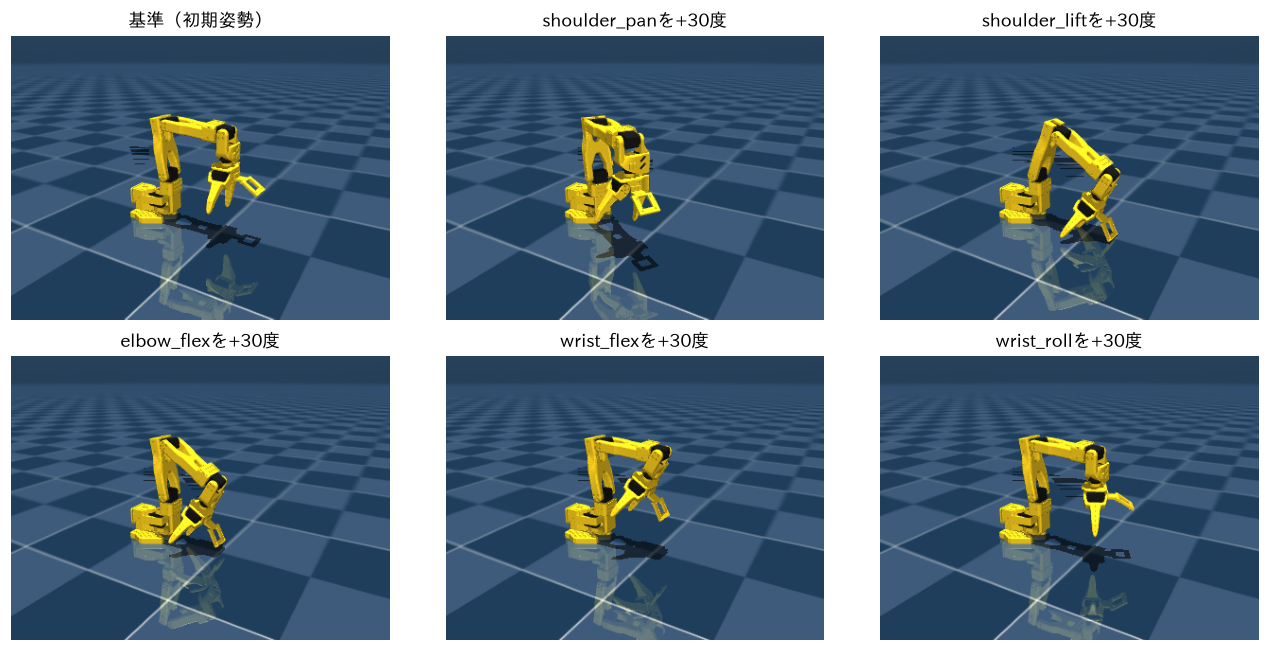

In [8]:
# 初期姿勢Q_INIT_PICKから、各関節だけを+30度動かした姿勢を描画する
# （グリッパーは見やすいように半開きにしておく）
base_pose = Q_INIT_PICK.copy()
base_pose[5] = 0.8
camera = make_camera(azimuth=120, elevation=-20, distance=0.75,
                     lookat=(0.15, 0.0, 0.12))
pose_renderer = PoseRenderer(height=300, width=400)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()
axes[0].imshow(pose_renderer.render(base_pose, camera))
axes[0].set_title("基準（初期姿勢）")
for j in range(5):
    pose = base_pose.copy()
    pose[j] += np.radians(30)
    axes[j + 1].imshow(pose_renderer.render(pose, camera))
    axes[j + 1].set_title(f"{JOINT_NAMES[j]}を+30度")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "02_joint_motion.png", bbox_inches="tight")
plt.show()

### 1.1 グリッパー角の向き

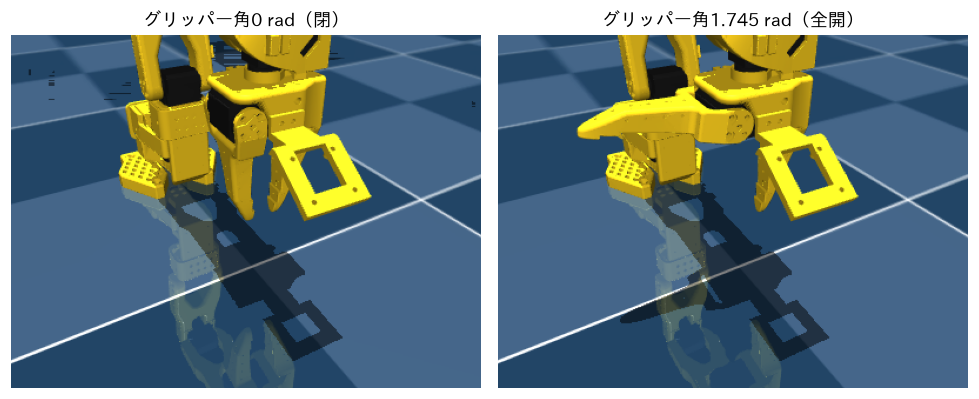

In [9]:
fixed_tip = mujoco.mj_name2id(robot_model, mujoco.mjtObj.mjOBJ_GEOM,
                              "fixed_jaw_sph_tip1")
moving_tip = mujoco.mj_name2id(robot_model, mujoco.mjtObj.mjOBJ_GEOM,
                               "moving_jaw_sph_tip1")

# グリッパー付近を拡大して描画するカメラ
ee_position = kin.fk(Q_INIT_PICK).translation
close_camera = make_camera(azimuth=150, elevation=-35, distance=0.30,
                           lookat=ee_position)

fig = plt.figure(figsize=(9, 3.6))
grid = fig.add_gridspec(1, 2)
for k, (angle, label) in enumerate([(SO101_GRIPPER_CLOSED, "0 rad（閉）"),
                                    (SO101_GRIPPER_OPEN, "1.745 rad（全開）")]):
    image = pose_renderer.render(np.r_[Q_INIT_PICK[:5], angle], close_camera)
    sub = fig.add_subplot(grid[k])
    sub.imshow(image)
    sub.set_title(f"グリッパー角{label}")
    sub.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "02_gripper_direction.png", bbox_inches="tight")
plt.show()

## 2. 初期姿勢と作業空間の中心

### 2.1 決め打ちした値

Grabetteの実演では、物体はテーブルの上にあり、人はテーブル面の近くまでグリッパーを下ろして掴む。

試行錯誤の結果、SO-101では、**先端をテーブル面の近くに置いた次の姿勢を初期姿勢として決め打ちすることとした**。
IKは各エピソードの最初のフレームをこの姿勢から解き始める。

作業空間の中心は、この姿勢の先端位置の近く[0.22, 0.00, 0.07] mに置く。Grabetteの軌跡は、重心がこの点に来るように配置する。

In [10]:
# 初期姿勢の先端位置をFKで計算する
init_pose = kin.fk(Q_INIT_PICK)
print("初期姿勢[deg]       :", np.round(np.degrees(Q_INIT_PICK[:5]), 1))
print("先端位置[m]         :", np.round(init_pose.translation, 3))
print("作業空間の中心[m]   :", WORKSPACE_CENTER)
distance_mm = np.linalg.norm(init_pose.translation - WORKSPACE_CENTER) * 1000
print(f"先端と中心の距離     : {distance_mm:.1f} mm")

初期姿勢[deg]       : [  0. -10.  15.  85. -90.]
先端位置[m]         : [ 0.211 -0.012  0.067]
作業空間の中心[m]   : [0.22 0.   0.07]
先端と中心の距離     : 15.3 mm


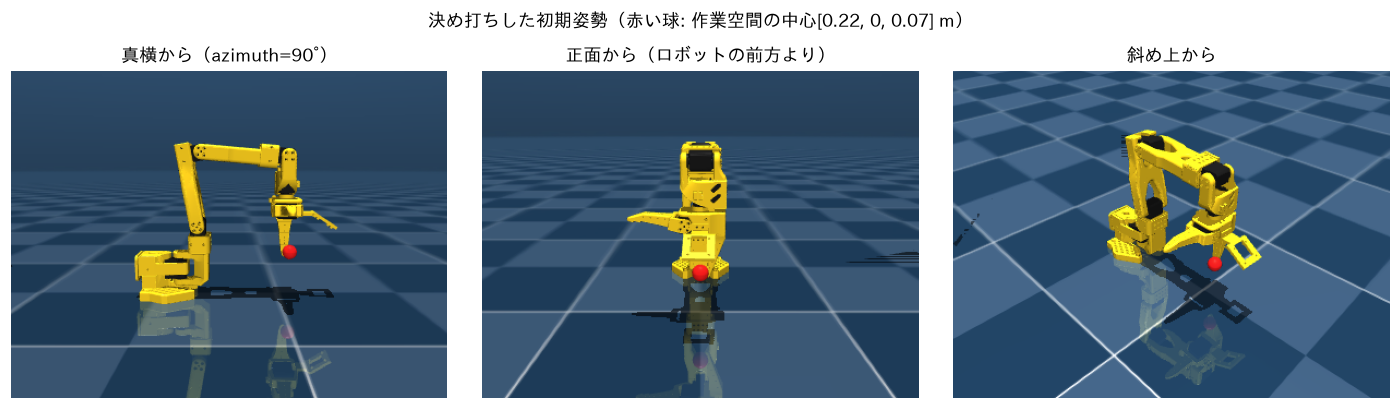

In [11]:
# 初期姿勢を3方向から描画する（赤い球 = 作業空間の中心）
pose = Q_INIT_PICK.copy()
pose[5] = SO101_GRIPPER_OPEN                 # 見やすいようにグリッパーを開く
markers = [(WORKSPACE_CENTER, (1.0, 0.1, 0.1, 0.8))]
views = [
    ("真横から（azimuth=90°）",
     make_camera(azimuth=90, elevation=-10, distance=0.65,
                 lookat=(0.12, 0, 0.10))),
    ("正面から（ロボットの前方より）",
     make_camera(azimuth=180, elevation=-15, distance=0.65,
                 lookat=(0.12, 0, 0.10))),
    ("斜め上から",
     make_camera(azimuth=135, elevation=-35, distance=0.70,
                 lookat=(0.12, 0, 0.08))),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, view) in zip(axes, views):
    ax.imshow(pose_renderer.render(pose, view, markers=markers))
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("決め打ちした初期姿勢（赤い球: 作業空間の中心[0.22, 0, 0.07] m）",
             y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / "02_initial_pose.png", bbox_inches="tight")
plt.show()

### 2.2 wrist_rollの−90° 固定可否

この関節は、先端の位置をほとんど変えない性質があるとみられる。
初期姿勢からwrist_rollだけを1回転させたときの先端の動きを、他の関節を動かした場合と比べる。

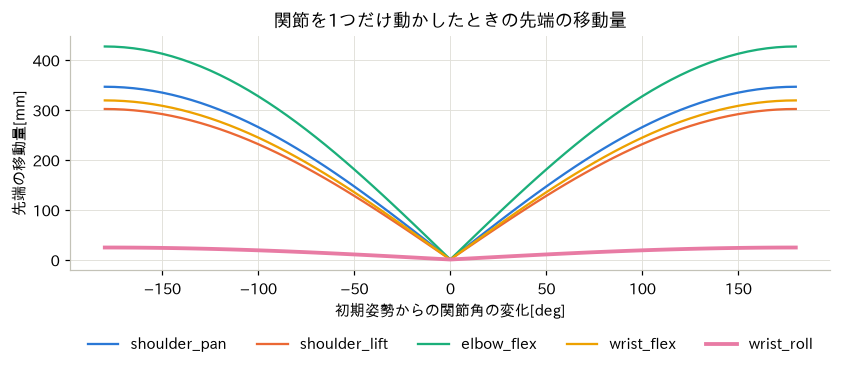

In [12]:
# 各関節を初期姿勢から−180〜+180度の範囲で1つずつ動かし、先端の移動量を測る
sweep = np.radians(np.linspace(-180, 180, 73))
fig, ax = plt.subplots(figsize=(8, 3.6))
for j in range(5):
    moves_mm = []
    for delta in sweep:
        q = Q_INIT_PICK.copy()
        q[j] = q[j] + delta          # 可動範囲を超える値も含めて、形だけを比べる
        moves_mm.append(np.linalg.norm(kin.fk(q).translation
                                       - init_pose.translation) * 1000)
    ax.plot(np.degrees(sweep), moves_mm, color=SERIES_COLORS[j],
            label=JOINT_NAMES[j], lw=2.5 if j == 4 else 1.5)
ax.set_xlabel("初期姿勢からの関節角の変化[deg]")
ax.set_ylabel("先端の移動量[mm]")
ax.set_title("関節を1つだけ動かしたときの先端の移動量")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout()
plt.savefig(OUT_DIR / "02_wrist_roll_effect.png", bbox_inches="tight")
plt.show()

wrist_roll =    +0 deg: ジョーの開く向き (X, Y, Z) = [ 0.96 -0.05  0.28]
wrist_roll =   -90 deg: ジョーの開く向き (X, Y, Z) = [-0.05 -0.96  0.28]


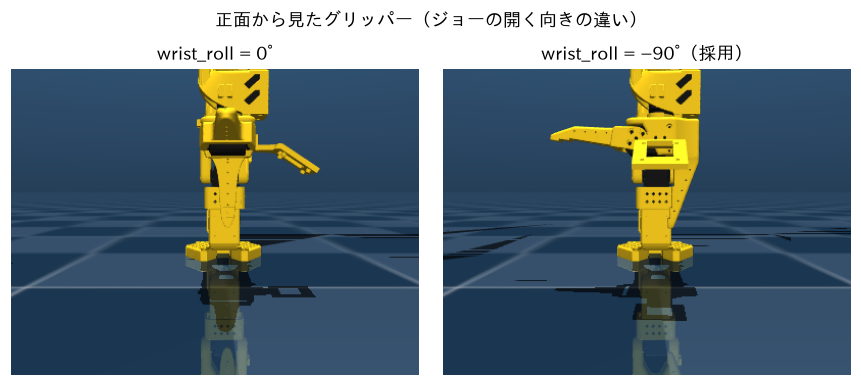

In [13]:
# wrist_rollを0° と−90° にしたとき、ジョーがどの向きに開くかを数値で確かめる
# （固定ジョー先端 → 可動ジョー先端 の向きを、ロボット座標系で表示する）
for roll in [0.0, WRIST_ROLL_FIXED]:
    robot_data.qpos[:6] = np.r_[Q_INIT_PICK[:4], roll, 1.0]
    mujoco.mj_forward(robot_model, robot_data)
    opening = (robot_data.geom_xpos[moving_tip]
               - robot_data.geom_xpos[fixed_tip])
    opening /= np.linalg.norm(opening)
    print(f"wrist_roll = {np.degrees(roll):+5.0f} deg: ジョーの開く向き "
          f"(X, Y, Z) = {np.round(opening, 2)}")

# wrist_rollを0° と−90° にした姿勢を、正面から並べて描画する
front = make_camera(azimuth=180, elevation=-5, distance=0.35,
                    lookat=init_pose.translation)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, roll, title in [(axes[0], 0.0, "wrist_roll = 0°"),
                        (axes[1], WRIST_ROLL_FIXED, "wrist_roll = −90°（採用）")]:
    q = Q_INIT_PICK.copy()
    q[4], q[5] = roll, SO101_GRIPPER_OPEN
    ax.imshow(pose_renderer.render(q, front))
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("正面から見たグリッパー（ジョーの開く向きの違い）", y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / "02_wrist_roll_views.png", bbox_inches="tight")
plt.show()

wrist_rollは1回転させても約24 mm（半径約12 mmの円）しか動かなかった。

IKにおいて、wrist_rollの値は先端位置の合わせ込みにほぼ寄与しないことが分かり、

かつ試行錯誤の過程で、wrist_rollが適切でない方向に動くパターンが多発したため

IKの後にwrist_rollを−90°（ジョーが左右に開く向き）に固定することとした。


## 3. SO-101の手が届く範囲

IKが解けるかどうかは、まず「目標がロボットの手の届く範囲にあるか」で決まる。
可動範囲内のランダムな関節角20,000個でFKを計算し、先端が届く範囲を描く。

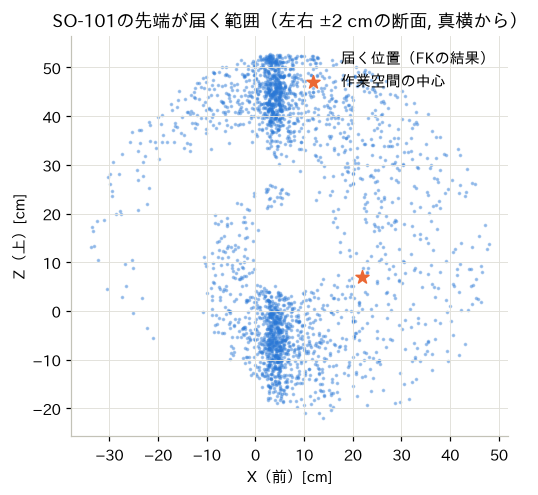

In [14]:
# ランダムな関節角で先端位置を集め、真横から見た図（X-Z平面）にする
rng = np.random.default_rng(1)
reach_points = np.array([kin.fk(rng.uniform(lower, upper)).translation
                         for _ in range(20000)])
# ロボットの正面付近（左右 ±2 cm）の点だけを使う
slice_mask = np.abs(reach_points[:, 1]) < 0.02

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(reach_points[slice_mask, 0] * 100,
           reach_points[slice_mask, 2] * 100,
           s=2, color=SERIES_COLORS[0], alpha=0.35, label="届く位置（FKの結果）")
ax.scatter(WORKSPACE_CENTER[0] * 100, WORKSPACE_CENTER[2] * 100, s=80,
           color=SERIES_COLORS[1], marker="*", label="作業空間の中心", zorder=3)
ax.set_xlabel("X（前）[cm]")
ax.set_ylabel("Z（上）[cm]")
ax.set_title("SO-101の先端が届く範囲（左右 ±2 cmの断面, 真横から）")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUT_DIR / "02_reachable_workspace.png", bbox_inches="tight")
plt.show()

作業空間の中心から30 cm前後で届かなくなるとみられる。Grabetteの軌跡は前後に20 cm以上広がるため、以降の変換では軌跡を縮小する。

## 4. IK（逆運動学）の成功と失敗

### 4.1 IKの計算の流れ

IKが失敗する原因は、大きく次の3つに分けられる。

| 種類 | 状況 | 起きること |
|---|---|---|
| A. 届かない | 目標が手の届く範囲の外にある | どの初期値から解いても、ずれが一定値から下がらない |
| B. 初期値によって解けない | 目標は届く範囲内だが、初期値の構えからでは関節の可動範囲などに阻まれる | 初期値を変えると解ける |
| C. 関節の可動範囲 | 目標に近づく方向へ関節を回したいが、可動範囲の端で止まる | 関節が端に張り付いたまま、ずれが残る |

以下、それぞれを可視化する。
IKの目標姿勢には初期姿勢の向きを使う

In [15]:
def solve_and_trace(target_position, q_init):
    """
    目標位置へIKを解き、結果と「反復ごとの位置誤差」の履歴を返す。

    目標姿勢には初期姿勢の向きを使う。
    成功の判定は5 mm（本研究のリターゲットと同じ基準）とする。
    """
    target = pin.SE3(init_pose.rotation, np.asarray(target_position, float))
    history = []
    q_sol, ok, err = kin.ik(target, q_init=q_init, pos_tol=5e-3,
                            history=history)
    return q_sol, ok, err, np.array(history)


def show_ik_case(title, target_position, cases, filename):
    """
    同じ目標に対して、複数の初期値からIKを解いた結果を図示する。

    左: 反復回数と位置誤差の関係（収束の様子）
    右: 各初期値から得られた最終姿勢の描画（赤い球 = 目標位置）
    """
    results = [(label, *solve_and_trace(target_position, q0))
               for label, q0 in cases]
    fig = plt.figure(figsize=(13, 3.6))
    grid = fig.add_gridspec(1, 1 + len(results),
                            width_ratios=[1.4] + [1] * len(results))
    ax = fig.add_subplot(grid[0])
    for k, (label, _, ok, err, history) in enumerate(results):
        ax.plot(history * 1000, color=SERIES_COLORS[k],
                label=f"{label}: {'成功' if ok else '失敗'} ({err * 1000:.1f} mm)")
    ax.axhline(5, color=COLOR_BAD, ls="--", lw=1)
    ax.text(0, 5, " 成功の基準5 mm", color=COLOR_BAD, va="bottom", fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel("反復回数")
    ax.set_ylabel("位置誤差[mm]（対数）")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
    view = make_camera(azimuth=90, elevation=-10, distance=0.75,
                       lookat=(0.18, 0, 0.12))
    for k, (label, q_sol, ok, err, _) in enumerate(results):
        sub = fig.add_subplot(grid[k + 1])
        sub.imshow(pose_renderer.render(
            q_sol, view, markers=[(target_position, (1, 0.1, 0.1, 0.9))]))
        sub.set_title(f"{label}\n→ {'成功' if ok else '失敗'}", fontsize=10)
        sub.axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, bbox_inches="tight")
    plt.show()
    return results

### 4.2 成功する例

作業空間の中心から少し前・上（+5 cm, +3 cm）の目標を、初期姿勢から解く。

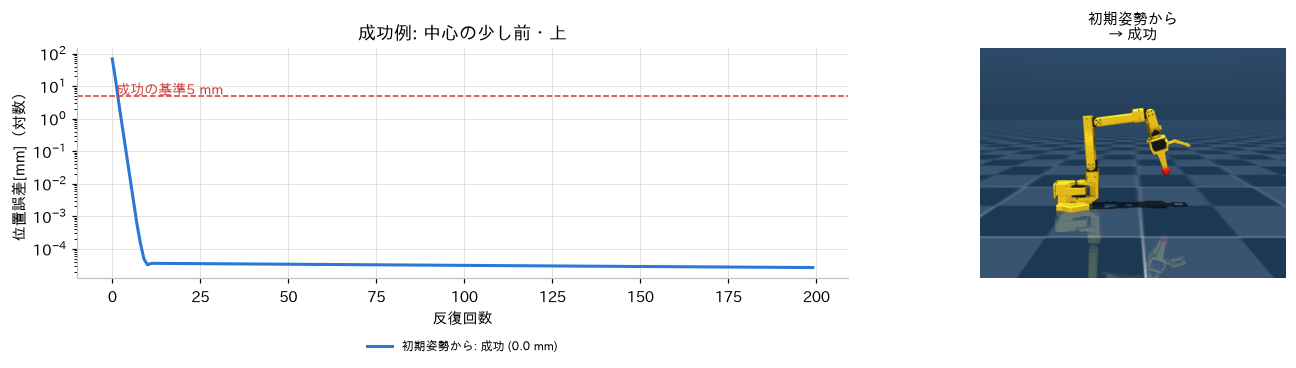

In [16]:
target_ok = WORKSPACE_CENTER + np.array([0.05, 0.0, 0.03])
_ = show_ik_case("成功例: 中心の少し前・上", target_ok,
                 [("初期姿勢から", Q_INIT_PICK.copy())], "02_ik_success.png")

### 4.3 失敗の種類A: 目標が届く範囲の外にある

ロボットの前方50 cm（届く範囲の外）を目標にする。初期値を3通り試す。

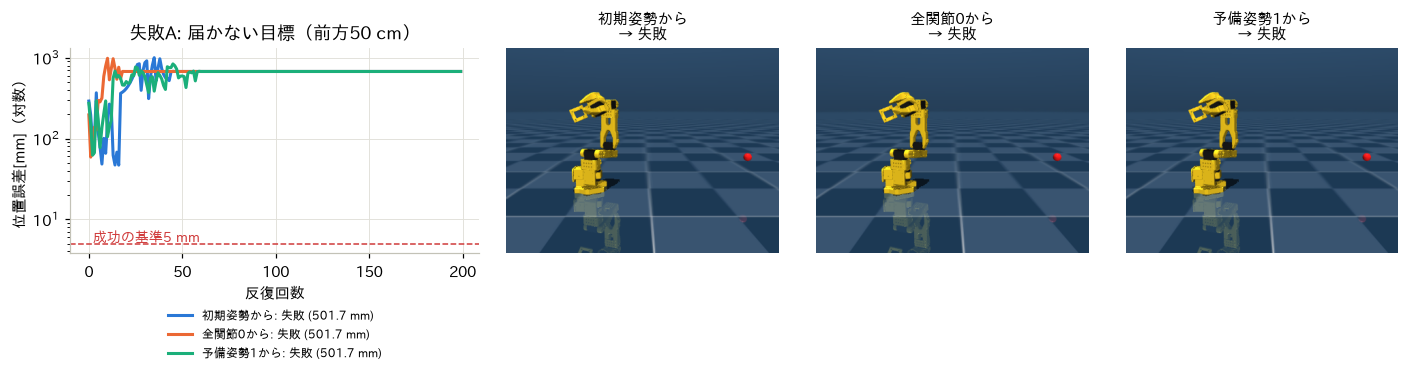

In [17]:
target_far = np.array([0.50, 0.0, 0.10])
_ = show_ik_case("失敗A: 届かない目標（前方50 cm）", target_far,
                 [("初期姿勢から", Q_INIT_PICK.copy()),
                  ("全関節0から", pin.neutral(kin.model)),
                  ("予備姿勢1から", Q_INIT_FALLBACKS[0].copy())],
                 "02_ik_fail_unreachable.png")

どの初期値から始めても腕は目標の方向へ伸び切った姿勢で止まり、誤差は減少しない。


### 4.4 IKが成功する範囲の地図

前出の関数を用い、3cm感覚の格子点の成功可否をプロットする

In [18]:
# 格子点ごとに、初期姿勢からIKを解いて成否と最終誤差を記録する
xs = np.arange(-0.06, 0.49, 0.03)
zs = np.arange(-0.15, 0.52, 0.03)
success_map = np.zeros((len(zs), len(xs)), dtype=bool)
error_map = np.zeros((len(zs), len(xs)))
for iz, z in enumerate(zs):
    for ix, x in enumerate(xs):
        _, ok, err, _ = solve_and_trace(np.array([x, 0.0, z]),
                                        Q_INIT_PICK.copy())
        success_map[iz, ix] = ok
        error_map[iz, ix] = err
print(f"成功した格子点: {success_map.sum()} / {success_map.size}")

成功した格子点: 225 / 437


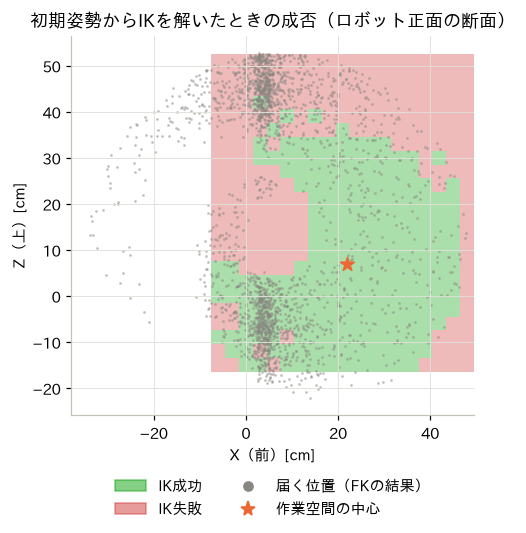

In [19]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(7.5, 5))
extent = [(xs[0] - 0.015) * 100, (xs[-1] + 0.015) * 100,
          (zs[0] - 0.015) * 100, (zs[-1] + 0.015) * 100]
ax.imshow(success_map, origin="lower", extent=extent, aspect="equal",
          cmap=ListedColormap([COLOR_BAD, COLOR_GOOD]), alpha=0.35,
          vmin=0, vmax=1)
ax.scatter(reach_points[slice_mask, 0] * 100,
           reach_points[slice_mask, 2] * 100,
           s=1, color=COLOR_MUTED, alpha=0.35)
ax.scatter(WORKSPACE_CENTER[0] * 100, WORKSPACE_CENTER[2] * 100, s=90,
           color=SERIES_COLORS[1], marker="*", zorder=3)
ax.set_xlabel("X（前）[cm]")
ax.set_ylabel("Z（上）[cm]")
ax.set_title("初期姿勢からIKを解いたときの成否（ロボット正面の断面）")
handles = [Patch(color=COLOR_GOOD, alpha=0.5, label="IK成功"),
           Patch(color=COLOR_BAD, alpha=0.5, label="IK失敗"),
           plt.Line2D([], [], marker="o", ls="", color=COLOR_MUTED,
                      label="届く位置（FKの結果）"),
           plt.Line2D([], [], marker="*", ls="", color=SERIES_COLORS[1],
                      markersize=10, label="作業空間の中心")]
ax.legend(handles=handles, loc="upper center", ncol=2,
          bbox_to_anchor=(0.5, -0.13))
plt.tight_layout()
plt.savefig(OUT_DIR / "02_ik_success_map.png", bbox_inches="tight")
plt.show()

届く位置以内にあっても、IKに失敗する点が存在する。以下にその要因について検討する

### 4.5 失敗の種類B・C: 初期値によって解けない／関節の可動範囲で止まる

初期姿勢からは失敗した格子点について、初期値を「全関節0」に変えて解き直してみる。
解き直して成功したものが、初期値に依存する失敗とみなせる。

In [20]:
# 初期姿勢からは失敗した格子点を、全関節0から解き直す
candidates = []
for iz, z in enumerate(zs):
    for ix, x in enumerate(xs):
        if success_map[iz, ix]:
            continue
        target_position = np.array([x, 0.0, z])
        if solve_and_trace(target_position, pin.neutral(kin.model))[1]:
            candidates.append((error_map[iz, ix], target_position))

print(f"初期姿勢からは失敗し、全関節0からは成功した格子点: {len(candidates)}個")
for err, position in candidates:
    print(f"  目標{np.round(position, 2)} m  初期姿勢からの誤差{err * 1000:.1f} mm")
# 初期姿勢からの誤差が最も大きいもの（失敗がはっきりしているもの）を例にする
target_branch = max(candidates, key=lambda item: item[0])[1]

初期姿勢からは失敗し、全関節0からは成功した格子点: 12個
  目標[ 0.03  0.   -0.12] m  初期姿勢からの誤差7.9 mm
  目標[-0.06  0.   -0.03] m  初期姿勢からの誤差65.6 mm
  目標[0.39 0.   0.27] m  初期姿勢からの誤差389.5 mm
  目標[0.06 0.   0.33] m  初期姿勢からの誤差12.1 mm
  目標[0.36 0.   0.33] m  初期姿勢からの誤差171.3 mm
  目標[0.03 0.   0.36] m  初期姿勢からの誤差75.3 mm
  目標[0.09 0.   0.36] m  初期姿勢からの誤差33.3 mm
  目標[0.12 0.   0.36] m  初期姿勢からの誤差79.6 mm
  目標[0.15 0.   0.36] m  初期姿勢からの誤差100.1 mm
  目標[0.03 0.   0.39] m  初期姿勢からの誤差210.5 mm
  目標[0.06 0.   0.39] m  初期姿勢からの誤差218.9 mm
  目標[0.12 0.   0.39] m  初期姿勢からの誤差203.3 mm


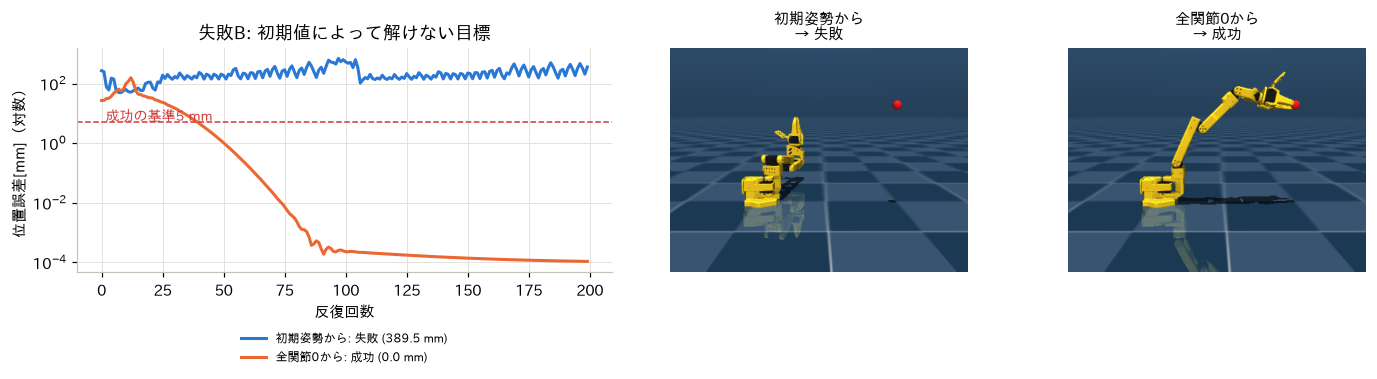

In [21]:
results_branch = show_ik_case(
    "失敗B: 初期値によって解けない目標", target_branch,
    [("初期姿勢から", Q_INIT_PICK.copy()),
     ("全関節0から", pin.neutral(kin.model))],
    "02_ik_fail_initial_value.png")

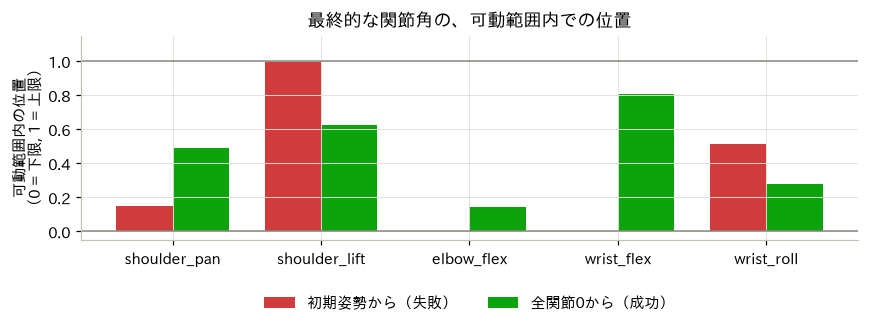

shoulder_pan     -77.6 deg
shoulder_lift   +100.0 deg  ← 可動範囲の端に張り付いている
elbow_flex       -96.8 deg  ← 可動範囲の端に張り付いている
wrist_flex       -95.0 deg  ← 可動範囲の端に張り付いている
wrist_roll        +5.1 deg


In [22]:
# 失敗した解と成功した解で、各関節が可動範囲のどこにあるかを比べる（種類Cの確認）
q_failed = results_branch[0][1]
q_solved = results_branch[1][1]


def position_in_range(q):
    """関節角を、可動範囲の下限 = 0、上限 = 1とした値に直す。"""
    return (q[:5] - lower[:5]) / (upper[:5] - lower[:5])


fig, ax = plt.subplots(figsize=(8, 3.2))
width = 0.38
x = np.arange(5)
ax.bar(x - width / 2, position_in_range(q_failed), width,
       color=COLOR_BAD, label="初期姿勢から（失敗）")
ax.bar(x + width / 2, position_in_range(q_solved), width,
       color=COLOR_GOOD, label="全関節0から（成功）")
ax.axhline(0, color=COLOR_MUTED, lw=1)
ax.axhline(1, color=COLOR_MUTED, lw=1)
ax.set_xticks(x, JOINT_NAMES[:5])
ax.set_ylabel("可動範囲内の位置\n（0 = 下限, 1 = 上限）")
ax.set_ylim(-0.05, 1.15)
ax.set_title("最終的な関節角の、可動範囲内での位置")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.savefig(OUT_DIR / "02_ik_joint_limits.png", bbox_inches="tight")
plt.show()

for name, q_value, low, high in zip(JOINT_NAMES[:5], q_failed, lower, upper):
    at_limit = min(abs(q_value - low), abs(q_value - high)) < np.radians(1)
    print(f"{name:14s} {np.degrees(q_value):+7.1f} deg"
          f"{'  ← 可動範囲の端に張り付いている' if at_limit else ''}")

初期姿勢から解くと、腕は目標とは違う構え（解の枝）へ進み、一部の関節が可動範囲の端に張り付いたまま止まる（種類C）。
また、同じ目標でも、初期姿勢で成否が変わることがある（種類B）

以上から、以降のデータ変換処理では次の方針でIKを解くことにした。

1. まず **前フレームの解** から解く。隣り合うフレームの目標は近いため、ほとんどのフレームはこれで解ける。
   また腕の構えが前フレームから連続するため、動きが滑らかになる。
2. 失敗したら、初期姿勢 → 予備姿勢3つ → 全関節0 → ランダム1回 の順に初期値を変えて解き直す（種類B・Cへの対策）。
3. それでも5 mm以内に届かないフレームは**IK失敗** として記録する。種類Aはこれでも救えない。